### Imports and dataset loading

In [64]:
import pandas as pd

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

dataset = load_dataset("fancyzhx/ag_news")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [65]:
full_train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print(f"Training shape: {full_train_df.shape}")
print(f"Testing shape: {test_df.shape}")

full_train_df.head(5)

Training shape: (120000, 2)
Testing shape: (7600, 2)


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


### Applying preprocessing decision

In [66]:
full_train_df["cleaned_text"] = full_train_df["text"].str.replace(
    "\\", " ", regex=False
)

test_df["cleaned_text"] = test_df["text"].str.replace(
    "\\", " ", regex=False
)

### Data Preparation and splitting

In [67]:
train_df, dev_df = train_test_split(
    full_train_df,
    test_size = 0.2,
    random_state = 42,
    stratify=full_train_df["label"]
)

### Verify the split and class distributions

In [68]:
print(f"Full training data: {full_train_df.shape}")
print(f"Training set: {train_df.shape}")
print(f"Development set: {dev_df.shape}")
print(f"Test set: {test_df.shape}")

Full training data: (120000, 3)
Training set: (96000, 3)
Development set: (24000, 3)
Test set: (7600, 3)


Checking the class distribution

In [69]:
print("Training class distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nDevelopment class distribution:")
print(dev_df["label"].value_counts().sort_index())

Training class distribution:
label
0    24000
1    24000
2    24000
3    24000
Name: count, dtype: int64

Development class distribution:
label
0    6000
1    6000
2    6000
3    6000
Name: count, dtype: int64


### Experiment 1: Baseline - Default TF-IDF

In [70]:
vectorizer = TfidfVectorizer()

X_train = vectorizer.fit_transform(train_df["cleaned_text"])
X_dev = vectorizer.transform(dev_df["cleaned_text"])

y_train = train_df["label"]
y_dev = dev_df["label"]

In [71]:
print("Training featue matrix:", X_train.shape)
print("Development featue matrix:", X_dev.shape)

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("First 20 features:", vectorizer.get_feature_names_out()[5000:5020])

Training featue matrix: (96000, 60004)
Development featue matrix: (24000, 60004)
Vocabulary size: 60004
First 20 features: ['aromatherapy' 'aron' 'aroon' 'arose' 'around' 'arouse' 'aroused'
 'arouses' 'arousing' 'arpey' 'arraigned' 'arraignment' 'arraignments'
 'arrange' 'arranged' 'arrangement' 'arrangements' 'arranges' 'arranging'
 'array']


Each row is an article and each columns is a token

### Train the baseline model

In [72]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### Make predictions on the development set

In [73]:
label_names = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

In [74]:
y_pred = model.predict(X_dev)
y_actual = list(y_dev)

for i in range(10):
    print(f"Prediction: {label_names[y_pred[i]]} | Actual: {label_names[y_actual[i]]}")

Prediction: Business | Actual: Business
Prediction: Sports | Actual: Sports
Prediction: Sports | Actual: Business
Prediction: Sci/Tech | Actual: Business
Prediction: World | Actual: World
Prediction: Sci/Tech | Actual: Sci/Tech
Prediction: Business | Actual: Business
Prediction: Sci/Tech | Actual: Sci/Tech
Prediction: Business | Actual: Business
Prediction: Sports | Actual: Sports


In [75]:
accuracy = accuracy_score(y_dev, y_pred)
print(f"Development Accuracy: {accuracy * 100:.4f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_dev,
        y_pred,
        target_names=["World", "Sports", "Business", "Sci/Tech"]
    )
)

Development Accuracy: 91.8125%

Classification Report:
              precision    recall  f1-score   support

       World       0.93      0.90      0.91      6000
      Sports       0.95      0.98      0.97      6000
    Business       0.90      0.88      0.89      6000
    Sci/Tech       0.90      0.90      0.90      6000

    accuracy                           0.92     24000
   macro avg       0.92      0.92      0.92     24000
weighted avg       0.92      0.92      0.92     24000



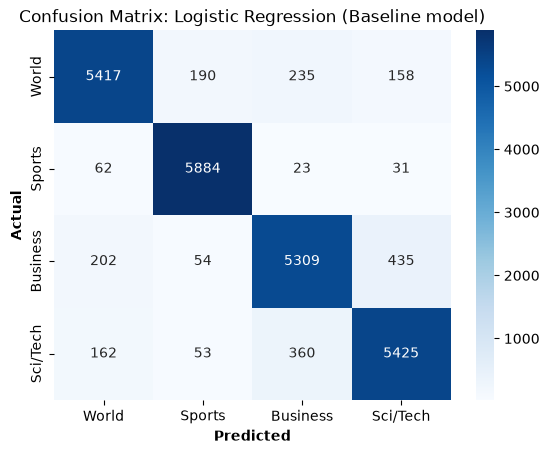

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

class_names = ["World", "Sports", "Business", "Sci/Tech"]

cm = confusion_matrix(y_dev, y_pred)
df_cm = pd.DataFrame(cm, index=class_names, columns=class_names)

sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted", weight='bold')
plt.ylabel("Actual", weight='bold')
plt.title("Confusion Matrix: Logistic Regression (Baseline model)")
plt.show()

the most interesting pattern is between **Business(2) and Sci/Tech(3)**

- 435 Sci/Tech articles were classified as Business
- 360 Business articles were classified as Sci/Tech

together that's **795 articles confused between Business and Sci/Tech**, the reason is because there might be an article about a technology company's earnings or a new product launch. So, they could contain vocabulary associated with both categories. Thats possible btw

In [77]:
misclassified = dev_df.loc[
    (y_dev == 3) & (y_pred == 2),
    ["cleaned_text", "label"]
].copy()

misclassified["predicted_labels"] = 2

for i in range(10):
    print(misclassified["cleaned_text"].iloc[i])
    actual_idx = misclassified["label"].iloc[i]
    predict_idx = misclassified["predicted_labels"].iloc[i]
    print(f"Actual: {class_names[actual_idx]} | Predicted: {class_names[predict_idx]}")
    print("-" * 80)

Nextel Wants Better FCC Deal Nextel Communications Inc. is pressing the Federal Communications Commission to revamp its controversial decision giving the cellular company new airwaves, seeking changes that according to 
Actual: Sci/Tech | Predicted: Business
--------------------------------------------------------------------------------
Sun, Kodak Look to Future Following Patent Suit Settlement In lieu of facing a court judgment of possibly more than US $1 billion, Sun Microsystems has agreed to pay  $92 million to settle a long-running patent infringement case with Eastman Kodak.
Actual: Sci/Tech | Predicted: Business
--------------------------------------------------------------------------------
Google Sets Possible Precedent for Future IPOs While Google Inc. (GOOG) made some well publicized mistakes leading up to its initial public offering, the IPO still brought in  $1.1 billion for the company and more than  $450 million for its founders and initial investors. But was the compan

**TF-IDF cpatures word importance, but does not truly understand an article's meaning or context**

"cleaned" articles contain strings like `#39;` and `amp;`, which are the artifacts of HTML entity, the model can encounter unusual encoders that do not match the clean text patterns we would prefer. This might be a **potential preprocessing improvement**, but we should not assume it will improve accuracy until we test it

### Decisions

**Observation**: the baseline achieves about 91.81% development accuracy, but it frequently confuses business and sci/tech

**Hypothesis**: decoding html entities may make the text more consistent and help the classifier lern more useful word features

**Experiment**: compare the current baseline with a version that decodes html entities, changing nothing else.

**Evaluation**: compare development accuracy and the confusion matrix for both versions.

### Experiment 2: Improved text cleaning

In [78]:
import html

full_train_df["decoded_text"] = full_train_df["cleaned_text"].apply(
    html.unescape
)

test_df["decoded_text"] = test_df["cleaned_text"].apply(
    html.unescape
)

In [79]:
full_train_df[["cleaned_text", "decoded_text"]].head(5)

,cleaned_text,decoded_text
0,Wall St. Bears Claw Back Into the Black (Reute...,Wall St. Bears Claw Back Into the Black (Reute...
1,Carlyle Looks Toward Commercial Aerospace (Reu...,Carlyle Looks Toward Commercial Aerospace (Reu...
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,Oil and Economy Cloud Stocks' Outlook (Reuters...
3,Iraq Halts Oil Exports from Main Southern Pipe...,Iraq Halts Oil Exports from Main Southern Pipe...
4,"Oil prices soar to all-time record, posing new...","Oil prices soar to all-time record, posing new..."


In [80]:
patterns = [r"#39;", r"amp;", r"&lt;", r"&gt;", r"&#39;", r"&amp;"]

for pattern in patterns:
    count = full_train_df["cleaned_text"].str.contains(
        pattern, regex=True, na=False
    ).sum()

    print(f"{pattern}: {count}")

#39;: 29696
amp;: 1467
&lt;: 5241
&gt;: 5243
&#39;: 0
&amp;: 0


In [81]:
mask = full_train_df["cleaned_text"].str.contains(
    r"#39;|amp;|&lt;|&gt;", regex=True, na=False
)

for text in full_train_df.loc[mask, "cleaned_text"].head(5):
    print(text[:300])
    print("-" * 80)

Universities to Build Largest Telescope (AP) AP - The University of Texas and Texas A amp;M University are planning to construct what they call the world's largest telescope with the help of a Houston businessman's  #36;1.25 million gift.
--------------------------------------------------------------------------------
HP: The Adaptive Enterprise that can't adapt &lt;strong&gt;Opinion&lt;/strong&gt; SAP hardly to blame
--------------------------------------------------------------------------------
Buffy the Censor Slayer &lt;strong&gt;Letters&lt;/strong&gt; Readers drive stake through parents' group
--------------------------------------------------------------------------------
Ashlee Vance: the readers have spoken &lt;strong&gt;Poll results&lt;/strong&gt; Bright news for resident &lt;em&gt;Reg&lt;/em&gt; ladyboy
--------------------------------------------------------------------------------
&lt;em&gt;El Reg&lt;/em&gt; pledges to name BSA antipiracy weasel &lt;strong&gt;Competition&l

In [82]:
mask = full_train_df["cleaned_text"].str.contains(
    "amp;", regex=False, na=False
)

for text in full_train_df.loc[mask, "cleaned_text"].head(10):
    print(text[:250])
    print("-" * 80)

Universities to Build Largest Telescope (AP) AP - The University of Texas and Texas A amp;M University are planning to construct what they call the world's largest telescope with the help of a Houston businessman's  #36;1.25 million gift.
--------------------------------------------------------------------------------
Stock lawsuit possible in telecom merger plan (USATODAY.com) USATODAY.com - Former MediaOne Group executives are exploring a class-action lawsuit over Cingular's insistence that AT amp;T Wireless stock options, issued by the millions to employees and
--------------------------------------------------------------------------------
Q amp;A: HP #39;s Livermore sees no need for HP-UX on x86 AUGUST 17, 2004 (COMPUTERWORLD) - This can #39;t be an easy time for Ann Livermore. When Hewlett-Packard Co. missed Wall Street #39;s earnings expectations late last week, the blame was placed
--------------------------------------------------------------------------------
Merrill survey o

In [83]:
import html
import re

def clean_html_artifacts(text):
    while True:
        decoded_text = html.unescape(text)
        if decoded_text == text:
            break
        text = decoded_text

    text = re.sub(r"#36;", "$", text)
    text = re.sub(r"\s*#39;\s*", "'", text)
    text = re.sub(r"\s+amp;\s*", "&", text)
    text = re.sub(r"\s*quot;\s*", '"', text)
    text = re.sub(
        r"</?(?:strong|em|b|i|p|div|br|span)\b[^>]*>",
        " ",
        text,
        flags=re.IGNORECASE
    )
    return re.sub(r"\s+", " ", text).strip()

In [84]:
full_train_df["experiment_text"] = full_train_df["cleaned_text"].apply(
    clean_html_artifacts
)

test_df["experiment_text"] = test_df["cleaned_text"].apply(
    clean_html_artifacts
)

mask = full_train_df["cleaned_text"].str.contains(
    r"amp;|#39;|#36;|&lt;|&gt;",
    regex=True,
    na=False
)
examples = full_train_df.loc[mask].head(5)

for _, row in examples.iterrows():
    print("BEFORE:", row["cleaned_text"][:250])
    print("AFTER: ", row["experiment_text"][:250])
    print("-" * 80)

BEFORE: Stocks End Up, But Near Year Lows (Reuters) Reuters - Stocks ended slightly higher on Friday but stayed near lows for the year as oil prices surged past  #36;46 a barrel, offsetting a positive outlook from computer maker Dell Inc. (DELL.O)
AFTER:  Stocks End Up, But Near Year Lows (Reuters) Reuters - Stocks ended slightly higher on Friday but stayed near lows for the year as oil prices surged past $46 a barrel, offsetting a positive outlook from computer maker Dell Inc. (DELL.O)
--------------------------------------------------------------------------------
BEFORE: Money Funds Fell in Latest Week (AP) AP - Assets of the nation's retail money market mutual funds fell by  #36;1.17 billion in the latest week to  #36;849.98 trillion, the Investment Company Institute said Thursday.
AFTER:  Money Funds Fell in Latest Week (AP) AP - Assets of the nation's retail money market mutual funds fell by $1.17 billion in the latest week to $849.98 trillion, the Investment Company Institute sa

| Corrupted text | Expected experiment result |
|---|---|
| `#36;1.25 million` | `$1.25 million` |
| `Web #39;s` | `Web's` |
| `wouldn #39;t` | `wouldn't` |
| `AT amp;T` | `AT&T` |
| `Texas A amp;M` | `Texas A&M` |
| `quot;He wouldn... quot;` | `"He wouldn't..."` |

In [85]:
train_df["experiment_text"] = full_train_df.loc[
    train_df.index, "experiment_text"
]
dev_df["experiment_text"] = full_train_df.loc[
    dev_df.index, "experiment_text"
]

In [86]:
mask = full_train_df["cleaned_text"].str.contains(
    "MSFT.O", regex=False, na=False
)

row = full_train_df.loc[mask].iloc[0]

print("BEFORE:", row["cleaned_text"][:250])
print("AFTER: ", row["experiment_text"][:250])

BEFORE: Microsoft to Introduce Cheaper Version of Windows  SEATTLE (Reuters) - Microsoft Corp. &lt;MSFT.O&gt; said it will  begin selling a stripped-down, low-cost version of its Windows  XP operating system in the emerging markets of Indonesia,  Malaysia an
AFTER:  Microsoft to Introduce Cheaper Version of Windows SEATTLE (Reuters) - Microsoft Corp. <MSFT.O> said it will begin selling a stripped-down, low-cost version of its Windows XP operating system in the emerging markets of Indonesia, Malaysia and Thailand


In [87]:
print("Original text:")
print(full_train_df["cleaned_text"].iloc[0][:300])

print("\nExperimental text:")
print(full_train_df["experiment_text"].iloc[0][:300])

Original text:
Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling band of ultra-cynics, are seeing green again.

Experimental text:
Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling band of ultra-cynics, are seeing green again.


In [88]:
# Fit TF-IDF using only the training data
experiment_vectorizer = TfidfVectorizer()

X_train_experiment = experiment_vectorizer.fit_transform(
    train_df["experiment_text"]
)

X_dev_experiment = experiment_vectorizer.transform(
    dev_df["experiment_text"]
)

print("Training matrix:", X_train_experiment.shape)
print("Development matrix:", X_dev_experiment.shape)

Training matrix: (96000, 60003)
Development matrix: (24000, 60003)


In [89]:
experiment_model = LogisticRegression(max_iter=1000)

experiment_model.fit(
    X_train_experiment,
    train_df["label"]
)

print("Experimental model training complete!")

Experimental model training complete!


In [90]:
y_pred_experiment = experiment_model.predict(X_dev_experiment)

experiment_accuracy = accuracy_score(
    dev_df["label"],
    y_pred_experiment
)

print(f"Experimental Development Accuracy: {experiment_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        dev_df["label"],
        y_pred_experiment,
        target_names=["World", "Sports", "Business", "Sci/Tech"]
    )
)

Experimental Development Accuracy: 0.9190

Classification Report:
              precision    recall  f1-score   support

       World       0.93      0.90      0.92      6000
      Sports       0.95      0.98      0.97      6000
    Business       0.89      0.89      0.89      6000
    Sci/Tech       0.90      0.90      0.90      6000

    accuracy                           0.92     24000
   macro avg       0.92      0.92      0.92     24000
weighted avg       0.92      0.92      0.92     24000



### Experiment 2 evaluation

Use the measured accuracy and classification report above to compare this model with the baseline.

Our hypothesis was that cleaning corrupted HTML artifacts and special characters might improve classification.

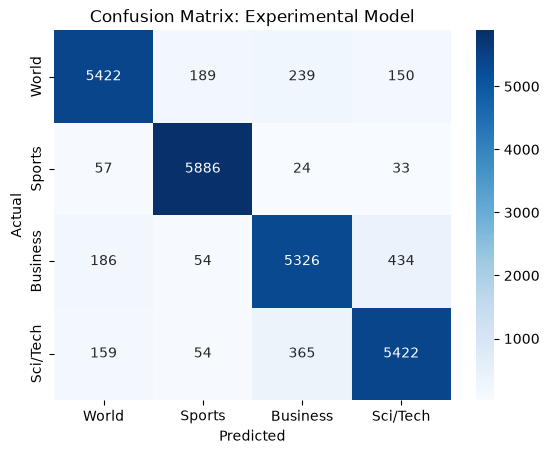

In [91]:
cm_experiment = confusion_matrix(
    dev_df["label"],
    y_pred_experiment
)

sns.heatmap(
    cm_experiment,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["World", "Sports", "Business", "Sci/Tech"],
    yticklabels=["World", "Sports", "Business", "Sci/Tech"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix: Experimental Model")
plt.show()

### what we have learned from experiment

**Experiment:** clean corrupted HTML artifacts and special characters

**Evaluation:** compare the measured development accuracy and class-level metrics with Experiment 1.

**Conclusion:** write the conclusion after rerunning the notebook and reviewing the updated metrics.


Experiment 3 changes the TF-IDF n-gram range while keeping the cleaned text and classifier settings fixed.

### Experiment 3: Unigrams + Bigrams

Keep Experiment 2's cleaned text and Logistic Regression settings, and change only TF-IDF to include two-word phrases.

In [92]:
bigram_vectorizer = TfidfVectorizer(ngram_range=(1, 2))

X_train_bigrams = bigram_vectorizer.fit_transform(
    train_df["experiment_text"]
)
X_dev_bigrams = bigram_vectorizer.transform(
    dev_df["experiment_text"]
)

print("Training matrix:", X_train_bigrams.shape)
print("Development matrix:", X_dev_bigrams.shape)

Training matrix: (96000, 1116425)
Development matrix: (24000, 1116425)


In [93]:
bigram_model = LogisticRegression(max_iter=1000)
bigram_model.fit(X_train_bigrams, train_df["label"])

y_pred_bigrams = bigram_model.predict(X_dev_bigrams)
bigram_accuracy = accuracy_score(dev_df["label"], y_pred_bigrams)

print(f"Experiment 3 Development Accuracy: {bigram_accuracy:.4f}")
print("\nClassification Report:")
print(
    classification_report(
        dev_df["label"],
        y_pred_bigrams,
        target_names=["World", "Sports", "Business", "Sci/Tech"]
    )
)

Experiment 3 Development Accuracy: 0.9182

Classification Report:
              precision    recall  f1-score   support

       World       0.93      0.90      0.92      6000
      Sports       0.95      0.98      0.96      6000
    Business       0.90      0.89      0.89      6000
    Sci/Tech       0.90      0.90      0.90      6000

    accuracy                           0.92     24000
   macro avg       0.92      0.92      0.92     24000
weighted avg       0.92      0.92      0.92     24000



In [94]:
results = pd.DataFrame({
    "Experiment": ["Baseline", "Improved cleaning", "Unigrams + bigrams"],
    "Development accuracy": [accuracy, experiment_accuracy, bigram_accuracy]
})
results

,Experiment,Development accuracy
0,Baseline,0.918125
1,Improved cleaning,0.919000
2,Unigrams + bigrams,0.918208


**Our conclusion**

for this experiment, adding bigrams provided almost no overall improvement.

our biagram experiment did not solve the business vs sci/tech confusion we identified earlier

this does not prove that bigrams are useless, their effectiveness depends on the dataset, vectorizer sttings, model. However, our experiments gives us little reason to keep this configuration as our preferred model